<a href="https://colab.research.google.com/github/arunimashiju/DSAlab/blob/main/Lab_06_dsa.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# LAB 06
import random
import time
import math
import pandas as pd
import matplotlib.pyplot as plt

random.seed(42)

In [2]:
class Node:
    def __init__(self, key, name):
        self.key = key
        self.name = name
        self.left = None
        self.right = None
        self.height = 1

In [3]:
class BST:
    def __init__(self):
        self.root = None
        self.comparisons = 0

    def insert(self, key, name):
        new = Node(key, name)

        if self.root is None:
            self.root = new
            return

        current = self.root

        while True:
            self.comparisons += 1

            if key < current.key:
                if current.left is None:
                    current.left = new
                    return
                current = current.left

            elif key > current.key:
                if current.right is None:
                    current.right = new
                    return
                current = current.right

            else:
                current.name = name
                return

    def search(self, key):
        current = self.root

        while current:
            self.comparisons += 1

            if key == current.key:
                return current.name
            elif key < current.key:
                current = current.left
            else:
                current = current.right

        return None

    def delete(self, key):
        parent = None
        current = self.root

        while current and current.key != key:
            parent = current

            if key < current.key:
                current = current.left
            else:
                current = current.right

        if current is None:
            return

        if current.left and current.right:
            successor_parent = current
            successor = current.right

            while successor.left:
                successor_parent = successor
                successor = successor.left

            current.key = successor.key
            current.name = successor.name

            if successor_parent == current:
                successor_parent.right = successor.right
            else:
                successor_parent.left = successor.right

            return

        if current.left:
            child = current.left
        else:
            child = current.right

        if parent is None:
            self.root = child
        elif parent.left == current:
            parent.left = child
        else:
            parent.right = child

    def height(self):
        if self.root is None:
            return -1

        maximum = 0
        stack = [(self.root, 0)]

        while stack:
            node, level = stack.pop()
            maximum = max(maximum, level)

            if node.left:
                stack.append((node.left, level + 1))
            if node.right:
                stack.append((node.right, level + 1))

        return maximum

    def inorder(self):
        result = []
        stack = []
        current = self.root

        while current or stack:
            while current:
                stack.append(current)
                current = current.left

            current = stack.pop()
            result.append(current.key)
            current = current.right

        return result


In [4]:
class AVL:
    def __init__(self):
        self.root = None
        self.comparisons = 0
        self.rotations = 0

    def get_height(self, node):
        return node.height if node else 0

    def update_height(self, node):
        node.height = 1 + max(
            self.get_height(node.left),
            self.get_height(node.right)
        )

    def balance_factor(self, node):
        return self.get_height(node.left) - self.get_height(node.right)

    def right_rotate(self, y):
        x = y.left
        y.left = x.right
        x.right = y

        self.update_height(y)
        self.update_height(x)
        self.rotations += 1

        return x

    def left_rotate(self, x):
        y = x.right
        x.right = y.left
        y.left = x

        self.update_height(x)
        self.update_height(y)
        self.rotations += 1

        return y

    def balance(self, node):
        self.update_height(node)
        bf = self.balance_factor(node)

        if bf > 1:
            if self.balance_factor(node.left) < 0:
                node.left = self.left_rotate(node.left)
            return self.right_rotate(node)

        if bf < -1:
            if self.balance_factor(node.right) > 0:
                node.right = self.right_rotate(node.right)
            return self.left_rotate(node)

        return node

    def insert_node(self, node, key, name):
        if node is None:
            return Node(key, name)

        self.comparisons += 1

        if key < node.key:
            node.left = self.insert_node(node.left, key, name)
        elif key > node.key:
            node.right = self.insert_node(node.right, key, name)
        else:
            node.name = name
            return node

        return self.balance(node)

    def insert(self, key, name):
        self.root = self.insert_node(self.root, key, name)

    def search(self, key):
        current = self.root

        while current:
            self.comparisons += 1

            if key == current.key:
                return current.name
            elif key < current.key:
                current = current.left
            else:
                current = current.right

        return None

    def find_min(self, node):
        while node.left:
            node = node.left
        return node

    def delete_node(self, node, key):
        if node is None:
            return None

        self.comparisons += 1

        if key < node.key:
            node.left = self.delete_node(node.left, key)
        elif key > node.key:
            node.right = self.delete_node(node.right, key)
        else:
            if node.left is None:
                return node.right
            if node.right is None:
                return node.left

            successor = self.find_min(node.right)
            node.key = successor.key
            node.name = successor.name
            node.right = self.delete_node(node.right, successor.key)

        return self.balance(node)

    def delete(self, key):
        self.root = self.delete_node(self.root, key)

    def height(self):
        return self.get_height(self.root) - 1

    def inorder(self):
        result = []
        stack = []
        current = self.root

        while current or stack:
            while current:
                stack.append(current)
                current = current.left

            current = stack.pop()
            result.append(current.key)
            current = current.right

        return result

    def is_balanced(self):
        def check(node):
            if node is None:
                return True

            if abs(self.balance_factor(node)) > 1:
                return False

            return check(node.left) and check(node.right)

        return check(self.root)

    def is_bst(self):
        values = self.inorder()
        return values == sorted(values) and len(values) == len(set(values))


In [15]:
def generate_datasets(n):
    sequential = list(range(1, n + 1))

    random_data = sequential.copy()
    random.shuffle(random_data)

    nearly_sorted = sequential.copy()

    for _ in range(int(n * 0.05)):
        i = random.randrange(n)
        j = random.randrange(n)
        nearly_sorted[i], nearly_sorted[j] = (
            nearly_sorted[j], nearly_sorted[i]
        )

    return sequential, random_data, nearly_sorted


rows = []

for n in [1000, 5000, 10000]:
    sequential, random_data, nearly_sorted = generate_datasets(n)

    for name, values in [
        ("Sequential", sequential),
        ("Random", random_data),
        ("Nearly Sorted", nearly_sorted)
    ]:
        for patient_id in values:
            rows.append([n, name, patient_id])

dataset_df = pd.DataFrame(
    rows,
    columns=["Size", "Dataset", "Patient_ID"]
)

dataset_df.to_csv("patient_dataset.csv", index=False)

print("Dataset CSV created!")
print(dataset_df.head())


from google.colab import files

files.download("patient_dataset.csv")



Dataset CSV created!
   Size     Dataset  Patient_ID
0  1000  Sequential           1
1  1000  Sequential           2
2  1000  Sequential           3
3  1000  Sequential           4
4  1000  Sequential           5


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [6]:

def run_experiment(values, n, dataset_name):
    bst = BST()
    avl = AVL()

    # Insert into BST
    start = time.perf_counter()
    for key in values:
        bst.insert(key, "Patient_" + str(key))
    bst_time = time.perf_counter() - start

    # Insert into AVL
    start = time.perf_counter()
    for key in values:
        avl.insert(key, "Patient_" + str(key))
    avl_time = time.perf_counter() - start

    bst_height = bst.height()
    avl_height = avl.height()
    rotations_before_delete = avl.rotations

    # Search 1000 existing IDs
    search_keys = random.Random(42 + n).sample(
        values, min(1000, n)
    )

    bst.comparisons = 0
    avl.comparisons = 0

    for key in search_keys:
        bst.search(key)
        avl.search(key)

    bst_avg = bst.comparisons / len(search_keys)
    avl_avg = avl.comparisons / len(search_keys)

    # Delete 20% of IDs
    delete_keys = random.Random(100 + n).sample(
        values, int(n * 0.20)
    )

    for key in delete_keys:
        bst.delete(key)
        avl.delete(key)

    assert avl.is_balanced()
    assert avl.is_bst()

    return {
        "Dataset": dataset_name,
        "Size": n,
        "BST Height": bst_height,
        "AVL Height": avl_height,
        "Minimum Height": math.floor(math.log2(n)),
        "BST Insert Time": round(bst_time, 6),
        "AVL Insert Time": round(avl_time, 6),
        "BST Avg Comparisons": round(bst_avg, 2),
        "AVL Avg Comparisons": round(avl_avg, 2),
        "AVL Insert Rotations": rotations_before_delete,
        "AVL Total Rotations": avl.rotations,
        "BST Height After Delete": bst.height(),
        "AVL Height After Delete": avl.height()
    }


In [14]:
results = []

for n in [1000, 5000, 10000]:
    for name in ["Sequential", "Random", "Nearly Sorted"]:

        values = dataset_df[
            (dataset_df["Size"] == n) &
            (dataset_df["Dataset"] == name)
        ]["Patient_ID"].tolist()

        print("Running:", name, "Size:", n)
        results.append(run_experiment(values, n, name))

df = pd.DataFrame(results)
display(df)

df.to_csv("BST_AVL_Comparison.csv", index=False)
print("Comparison CSV created!")

from google.colab import files

files.download("BST_AVL_Comparison.csv")

Running: Sequential Size: 1000
Running: Random Size: 1000
Running: Nearly Sorted Size: 1000
Running: Sequential Size: 5000
Running: Random Size: 5000
Running: Nearly Sorted Size: 5000
Running: Sequential Size: 10000
Running: Random Size: 10000
Running: Nearly Sorted Size: 10000


,Dataset,Size,BST Height,AVL Height,Minimum Height,BST Insert Time,AVL Insert Time,BST Avg Comparisons,AVL Avg Comparisons,AVL Insert Rotations,AVL Total Rotations,BST Height After Delete,AVL Height After Delete
0,Sequential,1000,999,9,9,0.062722,0.007141,500.50,8.99,990,994,799,9
1,Random,1000,19,11,9,0.001786,0.006660,12.47,9.20,684,749,19,10
2,Nearly Sorted,1000,94,11,9,0.003242,0.007563,25.45,9.43,1208,1248,74,10
3,Sequential,5000,4999,12,12,1.519888,0.043183,2523.41,11.38,4987,5026,3999,12
4,Random,5000,28,14,12,0.011643,0.039529,14.84,11.60,3519,3921,27,13
5,Nearly Sorted,5000,278,13,12,0.031557,0.047199,46.97,11.68,5956,6177,225,13
6,Sequential,10000,9999,13,13,7.703031,0.088034,5128.25,12.34,9986,10075,7999,13
7,Random,10000,30,15,13,0.027073,0.090179,16.32,12.70,6945,7660,28,15
8,Nearly Sorted,10000,599,14,13,0.116741,0.114095,88.73,12.56,12007,12525,468,14


Comparison CSV created!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

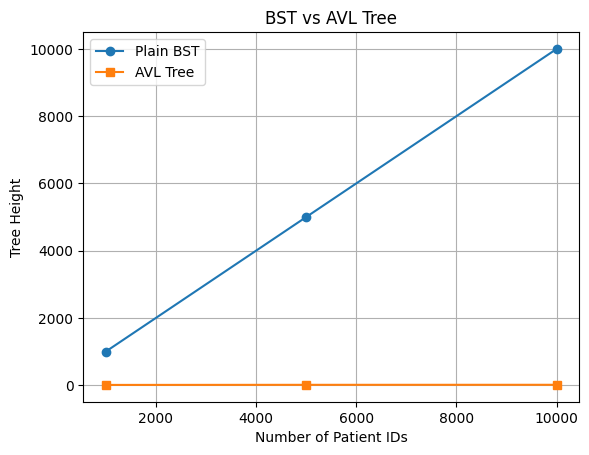

In [8]:
data = df[df["Dataset"] == "Sequential"]

plt.plot(data["Size"], data["BST Height"],
         marker="o", label="Plain BST")

plt.plot(data["Size"], data["AVL Height"],
         marker="s", label="AVL Tree")

plt.xlabel("Number of Patient IDs")
plt.ylabel("Tree Height")
plt.title("BST vs AVL Tree")
plt.legend()
plt.grid(True)
plt.show()


In [9]:
values = [10, 20, 30, 40, 50, 25]

bst = BST()
avl = AVL()

for value in values:
    bst.insert(value, "Patient_" + str(value))
    avl.insert(value, "Patient_" + str(value))

print("Plain BST")
print("Height:", bst.height())
print("In-order:", bst.inorder())

print("\nAVL Tree")
print("Height:", avl.height())
print("In-order:", avl.inorder())
print("Rotations:", avl.rotations)
print("Balanced:", avl.is_balanced())
print("BST property:", avl.is_bst())


Plain BST
Height: 4
In-order: [10, 20, 25, 30, 40, 50]

AVL Tree
Height: 2
In-order: [10, 20, 25, 30, 40, 50]
Rotations: 4
Balanced: True
BST property: True


In [10]:
class TreapNode:
    def __init__(self, key):
        self.key = key
        self.priority = random.random()
        self.left = None
        self.right = None


class Treap:
    def __init__(self):
        self.root = None
        self.rotations = 0

    def right_rotate(self, node):
        child = node.left
        node.left = child.right
        child.right = node
        self.rotations += 1
        return child

    def left_rotate(self, node):
        child = node.right
        node.right = child.left
        child.left = node
        self.rotations += 1
        return child

    def insert_node(self, root, key):
        if root is None:
            return TreapNode(key)

        if key < root.key:
            root.left = self.insert_node(root.left, key)

            if root.left.priority < root.priority:
                root = self.right_rotate(root)

        elif key > root.key:
            root.right = self.insert_node(root.right, key)

            if root.right.priority < root.priority:
                root = self.left_rotate(root)

        return root

    def insert(self, key):
        self.root = self.insert_node(self.root, key)

    def search(self, key):
        current = self.root

        while current:
            if key == current.key:
                return True
            elif key < current.key:
                current = current.left
            else:
                current = current.right

        return False

    def inorder(self):
        result = []
        stack = []
        current = self.root

        while current or stack:
            while current:
                stack.append(current)
                current = current.left

            current = stack.pop()
            result.append(current.key)
            current = current.right

        return result

    def height(self, node):
        if node is None:
            return -1

        return 1 + max(
            self.height(node.left),
            self.height(node.right)
        )


# Test the Treap
treap = Treap()

for i in range(1, 101):
    treap.insert(i)

print("Number of nodes:", len(treap.inorder()))
print("Treap height:", treap.height(treap.root))
print("Rotations:", treap.rotations)
print("Search 50:", treap.search(50))
print("Sorted order:", treap.inorder() == list(range(1, 101)))


Number of nodes: 100
Treap height: 12
Rotations: 95
Search 50: True
Sorted order: True
